<h1>2.23</h2>

$m = \frac{f(b)-f(a)}{b-a}$<br>
$y - f(a) = m (x-a) = \frac{f(b)-f(a)}{b-a} (x - a)$<br>

When $y = 0, x = c$, $0 - f(a) = \frac{f(b)-f(a)}{b-a} (c - a)$

$c - a = - \frac{f(a)}{\frac{f(b)-f(a)}{b-a}}$

$c = a - \frac{(b-a) f(a)}{f(b)-f(a)}$

Check the sign of f(c), replace one original endpoint whose function value has the same sign with f(c).

<h1>2.24</h2>

[-4, 11]
intersection = 1.8


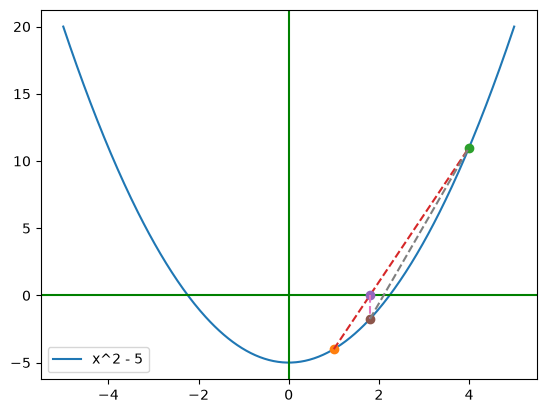

In [1]:
import matplotlib.pyplot as plt  
import numpy as np

x = np.linspace(-5, 5, 400)

def f(x):
    return x**2 - 5

interval = [1, 4]
points = [f(interval[0]), f(interval[1])]
m = (f(interval[1])-f(interval[0]))/(interval[1] - interval[0])
c = interval[0] - 1/m * f(interval[0])

print(points)
print("intersection =", c)

plt.plot(x, f(x), label = "x^2 - 5")
plt.axhline(y = 0, color = "green") 
plt.axvline(0, color = "green")
plt.plot(interval[0], points[0], "o")
plt.plot(interval[1], points[1], "o")
plt.plot(interval, points, linestyle = "dashed")

plt.plot(c, 0, "o")
plt.plot(c, f(c), "o")
plt.plot([c, c], [0, f(c)], linestyle = "dashed")

plt.plot([c, interval[1]], [f(c), points[1]], linestyle= "dashed")


plt.legend()
plt.show()

<h1>2.25</h2>

A simple linear function will make it easy to use the Regula Falsi method to find the root since it find the intersection of the chosen endpoints slope and the x-axis, only take one step.
If we can choose interval endpoints symmetrically and it's an nonlinear function with somewhere a rapidly changing slope, the Bisection Method does a better job.


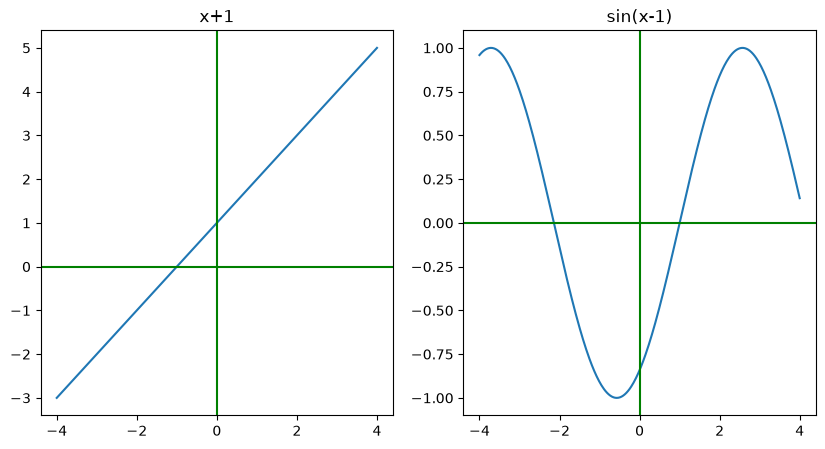

In [2]:
def f_2(x):
    return x + 1 

def f_3(x):
    return np.sin(x-1)

x = np.linspace(-4, 4, 400)

fig, axs = plt.subplots(1, 2, figsize = (10, 5))

axs[0].plot(x, f_2(x))
axs[0].set_title("x+1")
axs[0].axhline(0, color = "green")
axs[0].axvline(0, color = "green")

axs[1].plot(x, f_3(x))
axs[1].set_title("sin(x-1)")
axs[1].axhline(0, color = "green")
axs[1].axvline(0, color = "green")

print("A simple linear function will make it easy to use the Regula Falsi method to find the root since it find the intersection of the chosen endpoints slope and the x-axis, only take one step.")
print("If we can choose interval endpoints symmetrically and it's an nonlinear function with somewhere a rapidly changing slope, the Bisection Method does a better job.")

plt.show()

<h1>2.26 - 2.27</h2>

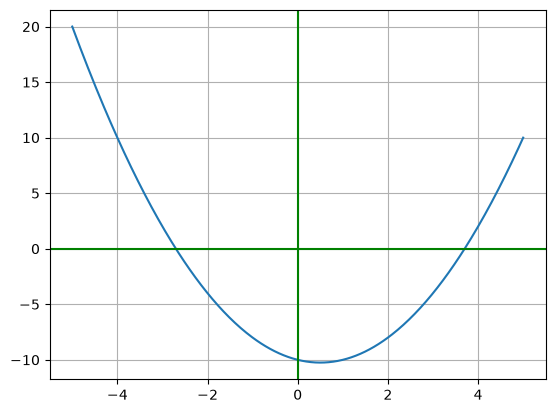

3.7015611532367423
-2.701561604432438


In [3]:
def RegulaFalsi(f, a, b, tol):
    '''
    f: continuous function
    a, b: for initial guess of the interval [a, b]
    tol: the tolerance for the root approximation, stop the loop when finding a value c such that |f(c)| < tol
    
    Initialize the interval by checking the function values have opposite signs over the initial endpoints.
        If f(a) and f(b) are of the same sign, print an error message.
    
    Iterate to approximate the root.
        For each iteration:
        Calculate the value c using the line intersection with the x-axis.
        Check if |f(c)| is less than the tolerance tol. If so, return c as the root approximation.
        
        Replace the endpoint that has the same sign as f(c).
        Update either a or b to the new value of c.
        Repeat until finding the root
    '''
    
    if np.sign(f(a)) == np.sign(f(b)):
        raise Exception("We cannot guarantee a root is between the given endpoints.")
    
    # Initialize c to ensure it is in the interval
    c = b 
    
    while True:
        c = a - ((b-a) * f(a))/(f(b)-f(a))
        
        if np.abs(f(c)) < tol:
            return c
        
        if np.sign(f(a)) == np.sign(f(c)):
            a = c
        elif np.sign(f(b)) == np.sign(f(c)):
            b = c
            
    return c


x = np.linspace(-5, 5, 400)

def function(x):
    return x**2 - x - 10


plt.plot(x, function(x))
plt.axhline(0, color="green")
plt.axvline(0, color = "green")
plt.grid(True)
plt.show()

fun = lambda x: x**2 - x - 10
        
root_1 = RegulaFalsi(fun, 0, 5, 1e-5)
print(root_1)

root_2 = RegulaFalsi(fun, -4, -2, 1e-5)
print(root_2)

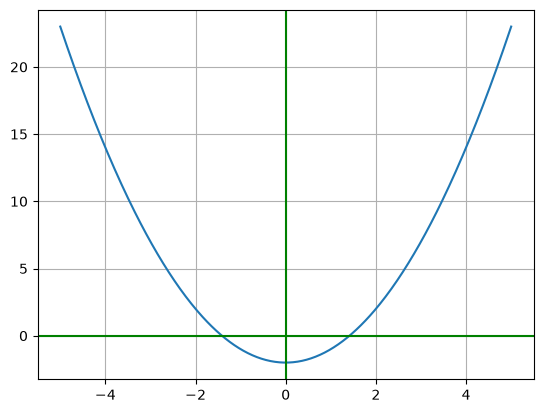

Approximation roots {root_1}: [1.0, 1.3333333333333333, 1.4, 1.411764705882353, 1.4137931034482758, 1.4141414141414141, 1.4142011834319528, 1.41421143847487, 1.4142131979695431, 1.4142134998513232, 1.4142135516460548, 1.4142135605326258, 1.4142135620573204, 1.4142135623189167, 1.4142135623637995, 1.4142135623715002, 1.4142135623728214, 1.414213562373048, 1.414213562373087, 1.4142135623730936, 1.414213562373095, 1.4142135623730951]
Approximation roots {root_2}: [1.0, 1.3333333333333333, 1.4, 1.411764705882353, 1.4137931034482758, 1.4141414141414141, 1.4142011834319528, 1.41421143847487, 1.4142131979695431, 1.4142134998513232, 1.4142135516460548, 1.4142135605326258, 1.4142135620573204, 1.4142135623189167, 1.4142135623637995, 1.4142135623715002, 1.4142135623728214, 1.414213562373048, 1.414213562373087, 1.4142135623730936, 1.414213562373095, 1.4142135623730951]


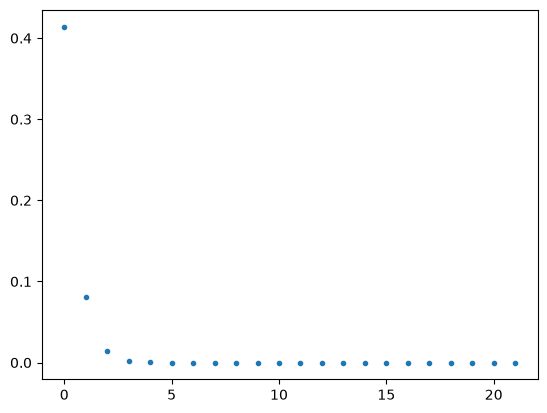

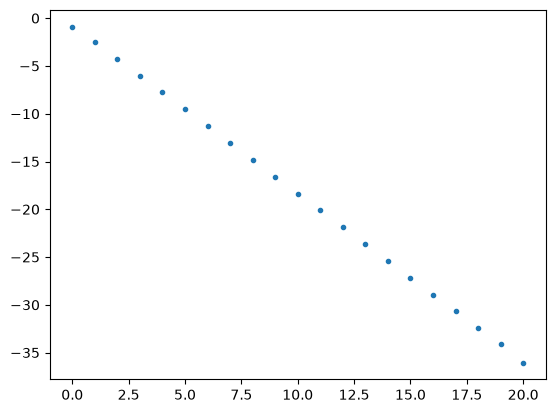

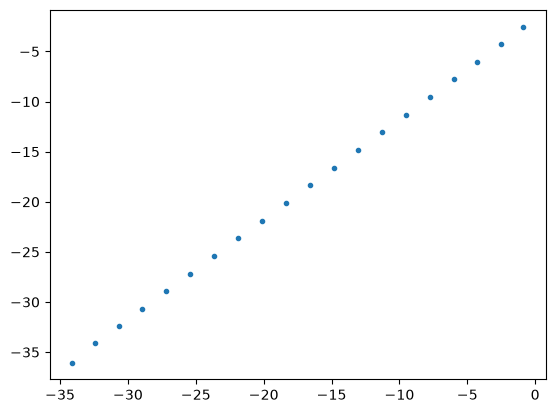

In [4]:
def regulafalsi(f, a, b, tol):
    if f(a)*f(b) > 0:
        raise Exception("...")
    
    width = b-a
    approx = []
    
    while width > tol:
        m = (f(b)-f(a))/(b-a)
        c = a - f(a)/m   
        
        approx.append(c)
        
        if f(a)*f(c) < 0:
            b = c
            
        elif f(b)*f(c) < 0:
            a = c
            
        elif f(c) ==0:
            a = c
            b = c
            
        width = b-a
            
    return c, approx

x = np.linspace(-5, 5, 400)

def function(x):
    return x**2 - 2


plt.plot(x, function(x))
plt.axhline(0, color="green")
plt.axvline(0, color = "green")
plt.grid(True)
plt.show()

fun = lambda x: x**2 -2

root_1, approx_1 = regulafalsi(fun, 0, 2, 1e-5)
root_2, approx_2 = regulafalsi(fun, 0, 2, 1e-5)

print("Approximation roots {root_1}:", approx_1)
print("Approximation roots {root_2}:", approx_2)

n_1 = len(approx_1)
n_2 = len(approx_2)

error_1 = []
error_2= []

for i in range(n_1):
    error_1.append(np.abs(approx_1[i] - np.sqrt(2)))

plt.plot(range(n_1), error_1, ".")
plt.show()

plt.plot(range(n_1), np.log(error_1), ".") 
plt.show()

for i in range(n_1):
    error_2.append(np.abs(approx_2[i] - np.sqrt(2)))
plt.plot(np.log(error_2[0:-1]), np.log(error_2[1:]), ".") 
plt.show()

